In [10]:
%matplotlib inline
import random
import torch
from matplotlib import pyplot as plt


In [11]:
def synthetic_data(w, b, num_examples):
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape((-1, 1))

true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)

In [12]:
print('features:', features[0],'\nlabel:', labels[0])
print('features:',features)

features: tensor([-0.1366, -1.0675]) 
label: tensor([7.5458])
features: tensor([[-0.1366, -1.0675],
        [-0.8623, -0.1461],
        [-0.3827, -0.9454],
        ...,
        [ 0.6060, -1.7625],
        [ 0.5965,  0.0968],
        [-0.6784, -1.4602]])


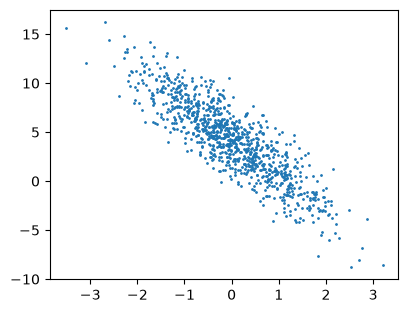

In [13]:
plt.figure(figsize=(4.5, 3.5))
plt.scatter(
    features[:, 1].detach().numpy(),
    labels.detach().numpy(),
    s = 1
)
plt.show()

In [17]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))

    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(
            indices[i:min(i+batch_size, num_examples)]
        )
        yield features[batch_indices], labels[batch_indices]

In [18]:
batch_size  = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-0.5668, -0.3501],
        [ 1.6727, -0.6566],
        [-0.1366, -1.0675],
        [-1.4077, -0.6290],
        [-0.5328, -0.5336],
        [-0.8986,  0.8659],
        [ 0.4632, -0.2438],
        [-0.7651,  0.4647],
        [-0.3784,  1.8830],
        [-0.2801, -0.6095]]) 
 tensor([[ 4.2511],
        [ 9.7851],
        [ 7.5458],
        [ 3.5217],
        [ 4.9489],
        [-0.5282],
        [ 5.9453],
        [ 1.0754],
        [-2.9663],
        [ 5.7089]])


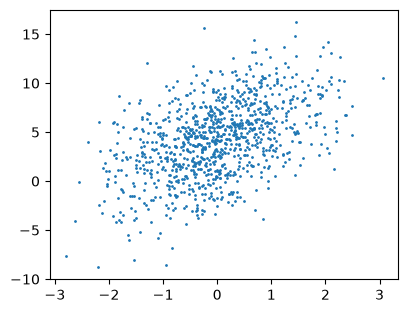

In [20]:
plt.figure(figsize=(4.5, 3.5))
plt.scatter(
    features[:, 0].detach().numpy(),
    labels.detach().numpy(),
    s = 1
)
plt.show()

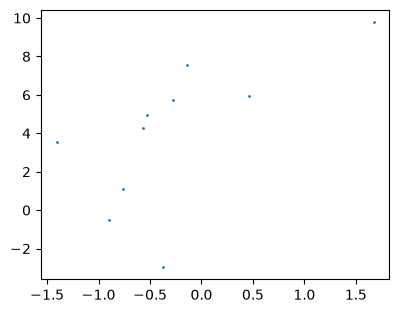

In [21]:
plt.figure(figsize=(4.5, 3.5))
plt.scatter(
    X[:,0].detach().numpy(),
    y.detach().numpy(),
    s = 1
)
plt.show()

In [23]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)


In [25]:
def linreg(X, w, b):
    return torch.matmul(X, w) + b

In [26]:
def squared_loss(y_hat, y):
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

In [ ]:
def sgd(params, lr, batch_size):
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()